# La météo peut-elle prévenir une crise de supply chain ?

**Projet 6 – ESME Sudria · module météo**

Ce notebook présente les résultats en six étapes, autour d'un cas fil rouge : **l'ouragan Helene et les mines de Spruce Pine** (septembre 2024).

Les calculs sont faits dans `meteo_supply_chain_v2.ipynb`, à exécuter **avant** celui-ci : il produit les fichiers du dossier `sorties/` que ce notebook se contente de lire.

In [1]:
# Préparation : chargement des résultats et mise en forme des graphiques (rien à présenter ici)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display

SORTIES = Path("sorties")
fichiers = {
    "jours": "meteo_indicateurs_journaliers.csv", "seuils": "meteo_seuils_par_site.csv",
    "validation": "meteo_validation_cas.csv", "episodes": "meteo_episodes_par_an.csv",
    "previsions": "meteo_helene_previsions.csv",
}
manquants = [f for f in fichiers.values() if not (SORTIES / f).exists()]
if manquants:
    raise FileNotFoundError("Exécutez d'abord meteo_supply_chain_v2.ipynb. Fichiers manquants : " + ", ".join(manquants))

jours = pd.read_csv(SORTIES / fichiers["jours"], parse_dates=["date"])
seuils = pd.read_csv(SORTIES / fichiers["seuils"])
validation = pd.read_csv(SORTIES / fichiers["validation"])
episodes = pd.read_csv(SORTIES / fichiers["episodes"], index_col="site")
previsions = pd.read_csv(SORTIES / fichiers["previsions"])

SEUIL = {(r.site, r.indicateur): r.seuil for r in seuils.itertuples()}
NOMS = {"pluie_3j": "pluie sur 3 jours", "pluie_90j": "pluie sur 3 mois", "rafales": "vent",
        "neige": "neige", "chaleur": "chaleur", "gel": "gel", "crue": "crue du fleuve",
        "basses_eaux": "niveau du fleuve"}
ARRET_HELENE = pd.Timestamp("2024-09-26")

BLEU, ORANGE, GRIS_CLAIR = "#2a78d6", "#eb6834", "#c9c8c2"
ROUGE, ENCRE, ENCRE_2, GRILLE = "#d03b3b", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "font.size": 10,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def dire(texte):
    """Affiche une phrase calculée à partir des résultats."""
    display(Markdown(texte))


def jours_txt(n):
    return f"{int(n)} jour" + ("s" if abs(int(n)) > 1 else "")

## 1. Le problème

Quand un fournisseur s'arrête, des usines s'arrêtent à l'autre bout du monde. Certains sites sont si concentrés qu'un seul événement météo suffit : la région de **Spruce Pine**, en Caroline du Nord, fournit plus de 80 % du quartz haute pureté commercial, indispensable à la fabrication des puces électroniques.

Le 26 septembre 2024, à l'approche de l'ouragan **Helene**, les mines ont été arrêtées.

**Notre question** : la météo aurait-elle permis de le voir venir, et combien de jours avant ?

## 2. Chaque site a sa propre météo « normale »

30 °C à Marseille en juillet, c'est normal ; à Oslo, c'est une canicule. De la même façon, une forte pluie ne se juge pas avec une règle unique.

Pour chaque site, on fixe donc un **seuil d'alerte : le niveau atteint seulement les 1 % de jours les plus extrêmes** de son histoire (2010-2020).

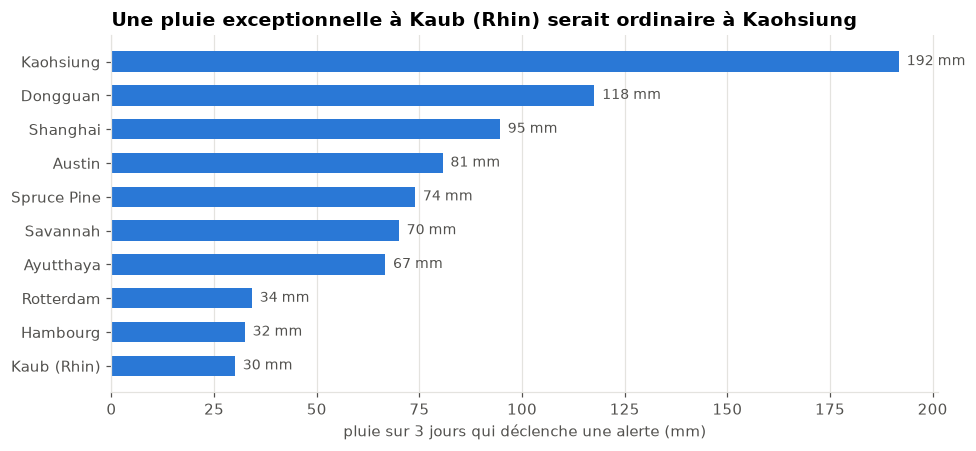

Il suffit de **30 mm** en 3 jours pour une pluie exceptionnelle à Kaub (Rhin), contre **192 mm** à Kaohsiung. Un seuil unique raterait l'un ou noierait l'autre d'alertes.

In [2]:
pluie = seuils[seuils["indicateur"] == "pluie_3j"].dropna().sort_values("seuil")
bas, haut = pluie.iloc[0], pluie.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(pluie["site"], pluie["seuil"], color=BLEU, height=0.6, zorder=2)
for y, v in enumerate(pluie["seuil"]):
    ax.text(v + pluie["seuil"].max() * 0.01, y, f"{v:.0f} mm", va="center", fontsize=9, color=ENCRE_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("pluie sur 3 jours qui déclenche une alerte (mm)")
ax.set_title(f"Une pluie exceptionnelle à {bas.site} serait ordinaire à {haut.site}")
fig.tight_layout()
plt.show()

dire(f"Il suffit de **{bas.seuil:.0f} mm** en 3 jours pour une pluie exceptionnelle à {bas.site}, "
     f"contre **{haut.seuil:.0f} mm** à {haut.site}. Un seuil unique raterait l'un ou noierait l'autre d'alertes.")

## 3. Helene : ce que montrait la météo mesurée

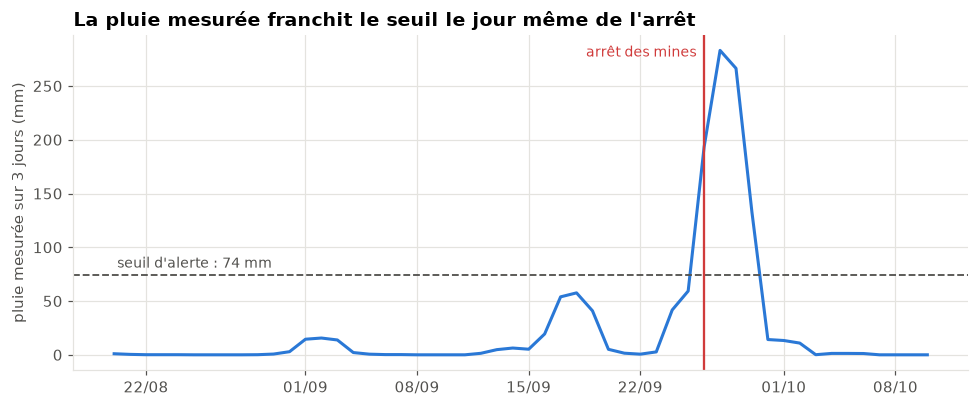

La pluie mesurée franchit le seuil **le jour même** de l'arrêt. C'est logique : l'arrêt était **préventif**, décidé à partir des **prévisions**. Surveiller ce qui s'est déjà passé ne suffit pas pour anticiper.

In [3]:
obs = validation[(validation["cas"] == "Ouragan Helene") & (validation["indicateur"] == "pluie_3j")
                 & validation["source"].str.startswith("observation")].iloc[0]
s_obs = SEUIL[("Spruce Pine", "pluie_3j")]
fen = jours[(jours["site"] == "Spruce Pine") & jours["date"].between("2024-08-20", "2024-10-10")]

if pd.isna(obs["jours_avance"]):
    titre, phrase = "La pluie mesurée ne franchit pas le seuil avant l'arrêt", "ne franchit pas le seuil avant l'arrêt"
elif obs["jours_avance"] <= 0:
    titre, phrase = "La pluie mesurée franchit le seuil le jour même de l'arrêt", "franchit le seuil **le jour même** de l'arrêt"
else:
    n = jours_txt(obs["jours_avance"])
    titre, phrase = f"La pluie mesurée ne franchit le seuil que {n} avant l'arrêt", f"ne franchit le seuil que **{n}** avant l'arrêt"

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(fen["date"], fen["pluie_3j"], color=BLEU, lw=2)
ax.axhline(s_obs, color=ENCRE_2, ls="--", lw=1.2)
ax.annotate(f"seuil d'alerte : {s_obs:.0f} mm", xy=(fen["date"].iloc[0], s_obs), xytext=(2, 5),
            textcoords="offset points", color=ENCRE_2, fontsize=9)
ax.axvline(ARRET_HELENE, color=ROUGE, lw=1.5)
ax.annotate("arrêt des mines", xy=(ARRET_HELENE, 1), xycoords=("data", "axes fraction"), xytext=(-5, -14),
            textcoords="offset points", ha="right", color=ROUGE, fontsize=9)
ax.set_ylabel("pluie mesurée sur 3 jours (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.set_title(titre)
fig.tight_layout()
plt.show()

dire(f"La pluie mesurée {phrase}. C'est logique : l'arrêt était **préventif**, décidé à partir des "
     "**prévisions**. Surveiller ce qui s'est déjà passé ne suffit pas pour anticiper.")

## 4. Helene : ce qu'annonçait la prévision

Les services météo archivent leurs prévisions. On peut donc retrouver ce qu'ils annonçaient **7 jours, 6 jours… 1 jour avant** pour la pluie du 25 au 27 septembre, et le comparer au seuil d'alerte.

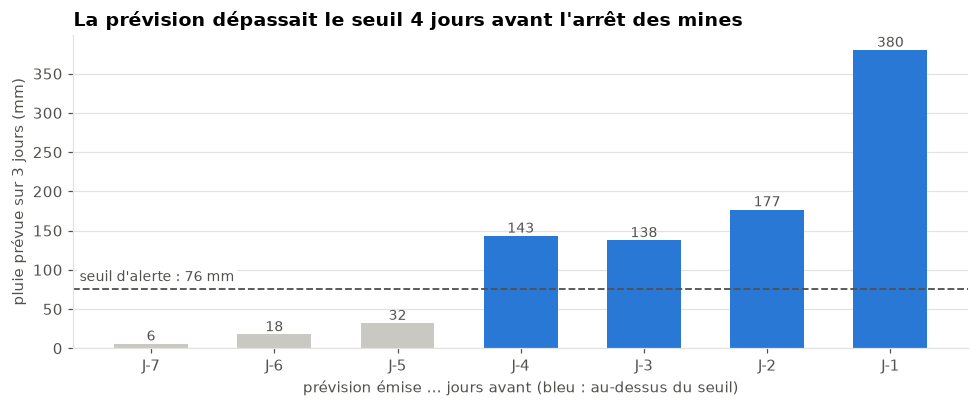

Dès **J-4**, la prévision annonçait une pluie au-dessus du seuil. À J-5, elle n'annonçait encore que 32 mm. C'est **4 jours** pour sécuriser du stock ou prévenir les clients.

In [4]:
p = previsions[previsions["avance"] != "J-0 (analyse)"].copy()
p["n"] = p["avance"].str.extract(r"J-(\d)").astype(int)
p = p.sort_values("n", ascending=False)
s_prev = previsions["seuil_mm"].iloc[0]

# avance = plus longue suite ininterrompue de prévisions au-dessus du seuil, en partant de J-1
avance = 0
for n in range(1, 8):
    ligne = p[p["n"] == n]
    if len(ligne) and ligne["pluie_prevue_3j_mm"].iloc[0] > s_prev:
        avance = n
    else:
        break

couleurs = [BLEU if v > s_prev else GRIS_CLAIR for v in p["pluie_prevue_3j_mm"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(p["avance"], p["pluie_prevue_3j_mm"], color=couleurs, width=0.6, zorder=2)
ax.grid(axis="x", visible=False)
ax.axhline(s_prev, color=ENCRE_2, ls="--", lw=1.2)
ax.annotate(f"seuil d'alerte : {s_prev:.0f} mm", xy=(0, s_prev), xycoords=("axes fraction", "data"),
            xytext=(4, 5), textcoords="offset points", ha="left", color=ENCRE_2, fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=4)
for x, v in enumerate(p["pluie_prevue_3j_mm"]):
    ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=ENCRE_2)
ax.set_xlabel("prévision émise … jours avant (bleu : au-dessus du seuil)")
ax.set_ylabel("pluie prévue sur 3 jours (mm)")
ax.set_title(f"La prévision dépassait le seuil {jours_txt(avance)} avant l'arrêt des mines" if avance
             else "Aucune prévision ne dépassait le seuil avant l'arrêt des mines")
fig.tight_layout()
plt.show()

if avance:
    avant = p[p["n"] == avance + 1]["pluie_prevue_3j_mm"]
    complement = f" À J-{avance + 1}, elle n'annonçait encore que {avant.iloc[0]:.0f} mm." if len(avant) else ""
    dire(f"Dès **J-{avance}**, la prévision annonçait une pluie au-dessus du seuil.{complement} "
         f"C'est **{jours_txt(avance)}** pour sécuriser du stock ou prévenir les clients.")
else:
    dire("Sur ce cas, la prévision n'aurait pas donné d'avance : à mentionner honnêtement dans le rapport.")

## 5. La même méthode sur quatre crises réelles

| Crise | Site | Ce qui s'est passé |
| --- | --- | --- |
| Ouragan Helene (2024) | Spruce Pine, États-Unis | Arrêt préventif des mines de quartz |
| Tempête hivernale Uri (2021) | Austin, États-Unis | Usine de semi-conducteurs Samsung à l'arrêt |
| Basses eaux du Rhin (2022) | Kaub, Allemagne | Barges qui ne desservent plus Cologne et Düsseldorf |
| Inondations en Thaïlande (2011) | Ayutthaya | Zones industrielles inondées |

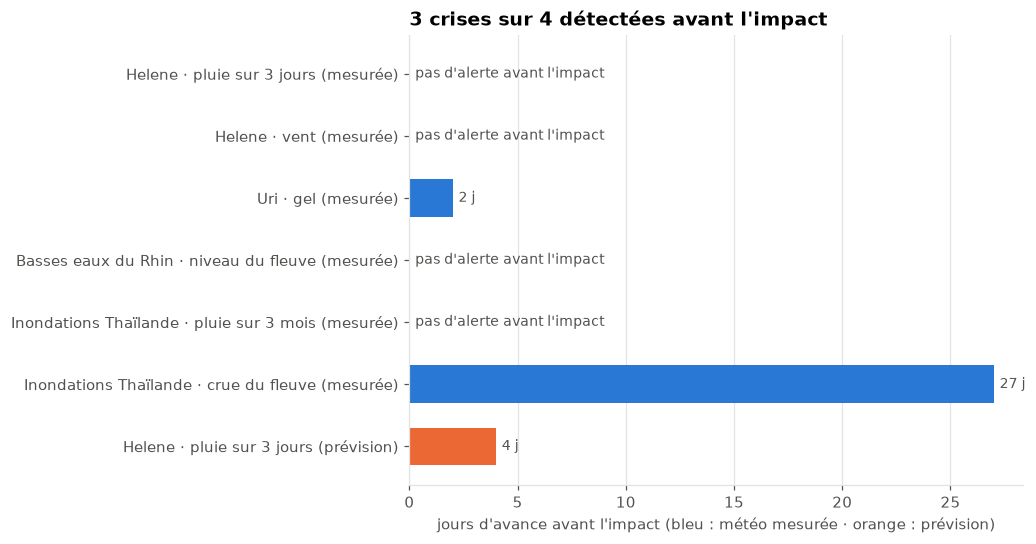

**3 crises sur 4** sont détectées avant l'impact par au moins un indicateur.

- **Thaïlande** : la pluie locale ne détecte pas l'inondation, car l'eau venait de l'amont du fleuve. Le débit du fleuve, lui, alerte **27 jours avant**.
- **Rhin** : pas d'alerte. Notre seuil (les 1 % de jours les plus bas de 2010-2020) correspond au niveau de la sécheresse record de 2018. Il convient aux événements soudains, mais il est trop strict pour un risque lent comme une sécheresse : il faudra un seuil métier, fondé sur la navigabilité du fleuve.

In [5]:
v = validation.copy()
est_prev = ~v["source"].str.startswith("observation")
v["libelle"] = (v["cas"].str.replace("Ouragan ", "").str.replace("Tempête hivernale ", "") + " · "
                + v["indicateur"].map(NOMS) + np.where(est_prev, " (prévision)", " (mesurée)"))
v["avance"] = np.where(v["alerte_avant_perturbation"], v["jours_avance"], 0)
v = v.iloc[::-1].reset_index(drop=True)
est_prev = ~v["source"].str.startswith("observation")

fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(v) + 1.2))
ax.barh(range(len(v)), v["avance"], color=np.where(est_prev, ORANGE, BLEU), height=0.6, zorder=2)
ax.set_yticks(range(len(v)), v["libelle"])
for y, r in v.iterrows():
    texte = f"{int(r.avance)} j" if r.alerte_avant_perturbation else "pas d'alerte avant l'impact"
    ax.text(r.avance + max(v["avance"].max(), 1) * 0.01, y, texte, va="center", fontsize=9, color=ENCRE_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("jours d'avance avant l'impact (bleu : météo mesurée · orange : prévision)")

par_cas = validation.groupby("cas")["alerte_avant_perturbation"].any()
ax.set_title(f"{par_cas.sum()} crises sur {len(par_cas)} détectées avant l'impact")
fig.tight_layout()
plt.show()

crue = validation[(validation["cas"] == "Inondations Thaïlande") & (validation["indicateur"] == "crue")].iloc[0]
dire(f"**{par_cas.sum()} crises sur {len(par_cas)}** sont détectées avant l'impact par au moins un indicateur.\n\n"
     f"- **Thaïlande** : la pluie locale ne détecte pas l'inondation, car l'eau venait de l'amont du fleuve. "
     f"Le débit du fleuve, lui, alerte **{jours_txt(crue['jours_avance'])} avant**.\n"
     "- **Rhin** : pas d'alerte. Notre seuil (les 1 % de jours les plus bas de 2010-2020) correspond au niveau "
     "de la sécheresse record de 2018. Il convient aux événements soudains, mais il est trop strict pour un "
     "risque lent comme une sécheresse : il faudra un seuil métier, fondé sur la navigabilité du fleuve.")

## 6. Combien d'alertes par an ?

Un système qui alerte toutes les semaines n'est pas utilisable. On compte donc combien de fois chaque site serait passé en alerte, en moyenne, chaque année.

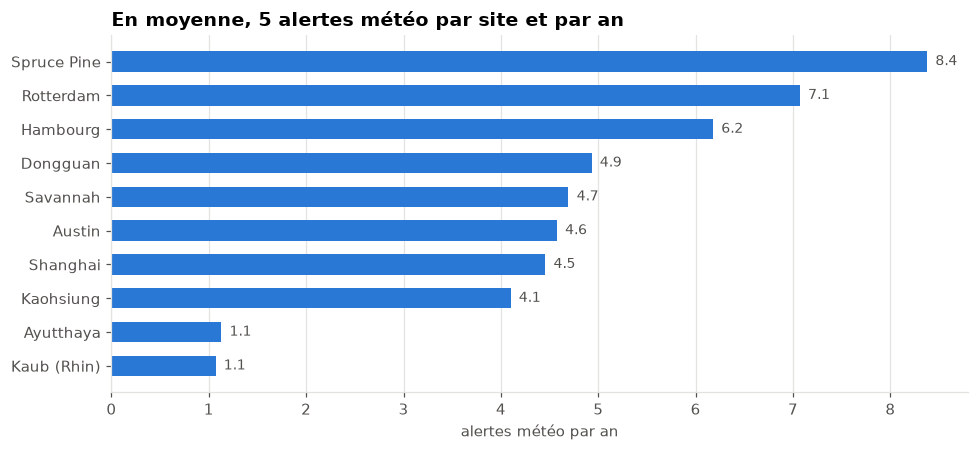

Pour 10 sites, cela fait environ **47 alertes par an**. La météo ne doit donc pas déclencher seule une alerte critique : elle **fait monter la note de risque** du fournisseur. C'est le graphe (ce site est-il critique pour nous ?) et les stocks (combien de jours de couverture ?) qui décident si l'alerte remonte jusqu'à l'acheteur.

In [6]:
tot = episodes["total_par_site"].sort_values()
moyenne, total = tot.mean(), tot.sum()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(tot.index, tot.values, color=BLEU, height=0.6, zorder=2)
for y, val in enumerate(tot.values):
    ax.text(val + tot.max() * 0.01, y, f"{val:.1f}", va="center", fontsize=9, color=ENCRE_2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("alertes météo par an")
ax.set_title(f"En moyenne, {moyenne:.0f} alertes météo par site et par an")
fig.tight_layout()
plt.show()

dire(f"Pour {len(tot)} sites, cela fait environ **{total:.0f} alertes par an**. La météo ne doit donc pas "
     "déclencher seule une alerte critique : elle **fait monter la note de risque** du fournisseur. "
     "C'est le graphe (ce site est-il critique pour nous ?) et les stocks (combien de jours de couverture ?) "
     "qui décident si l'alerte remonte jusqu'à l'acheteur.")

## Ce qu'on retient

In [7]:
obs_txt = ("le jour même" if pd.notna(obs["jours_avance"]) and obs["jours_avance"] <= 0
           else (f"{jours_txt(obs['jours_avance'])} avant" if pd.notna(obs["jours_avance"]) else "pas avant l'arrêt"))
avance_obs = obs["jours_avance"] if pd.notna(obs["jours_avance"]) else 0
if avance > max(avance_obs, 0):
    point2 = (f"**La prévision fait la différence.** Pour Helene, la météo mesurée alertait {obs_txt} ; "
              f"la prévision, **{jours_txt(avance)} avant**.")
else:
    point2 = (f"**La prévision n'a pas apporté d'avance sur Helene** (mesurée : {obs_txt} ; "
              f"prévision : {jours_txt(avance)}). Un point à creuser.")
if par_cas.all():
    point3 = f"**La méthode fonctionne sur des crises variées** : {len(par_cas)} sur {len(par_cas)} détectées avant l'impact."
else:
    rates = ", ".join(par_cas[~par_cas].index)
    point3 = (f"**La méthode fonctionne sur une partie des crises** : {par_cas.sum()} sur {len(par_cas)} "
              f"détectées avant l'impact. Non détectée(s) : {rates}.")
dire(f"""
1. **Juger chaque site par rapport à sa propre météo.** Un seuil unique ne fonctionne pas.
2. {point2}
3. {point3}
4. **La météo est un signal de fond, pas une alerte à elle seule** : environ {moyenne:.0f} alertes par site et par an, à croiser avec le graphe des fournisseurs et les stocks.
""")


1. **Juger chaque site par rapport à sa propre météo.** Un seuil unique ne fonctionne pas.
2. **La prévision fait la différence.** Pour Helene, la météo mesurée alertait le jour même ; la prévision, **4 jours avant**.
3. **La méthode fonctionne sur une partie des crises** : 3 sur 4 détectées avant l'impact. Non détectée(s) : Basses eaux du Rhin.
4. **La météo est un signal de fond, pas une alerte à elle seule** : environ 5 alertes par site et par an, à croiser avec le graphe des fournisseurs et les stocks.


**Limites**

- Quatre crises montrent que la méthode **peut** marcher, pas qu'elle est fiable en toutes circonstances.
- La météo mesurée vient d'une grille d'environ 25 km, qui adoucit les extrêmes locaux.
- Les prévisions archivées ne remontent qu'à 2024 : seul Helene a pu être testé en prévision.

**Prochaine étape** : brancher la note météo de chaque site dans le graphe des fournisseurs, avec les stocks, pour décider quelles alertes remontent.

---

*Données : [Open-Meteo](https://open-meteo.com/) (CC BY 4.0), réanalyse ERA5 et débits GloFAS (Copernicus). Pour exporter cette présentation sans le code :* `jupyter nbconvert --to html --no-input presentation_meteo.ipynb`